IMDLIB 0.3 adds two new features: one function to load data, and built-in regions. Together, they give daily rainfall and temperature for any state, district, river basin or city in India, as shown below with IMD data.

## load()

`imd.load()` downloads IMD gridded data, keeps the files in a local cache and reads them when the data is first used. Loading the same period again needs no download.

In [1]:
import imdlib as imd

data = imd.load('rain', 2020, 2024)
tmax = imd.load('tmax', '2024-04-01', '2024-06-30')   # part of a year

## Real-time data

IMD also publishes provisional daily data for recent days, which `source='realtime'` loads.

In [2]:
recent = imd.load('rain', '2026-10-01', '2026-10-07', source='realtime')
recent.region(state='Kerala').round(1)

,Kerala
2026-10-01,0.7
2026-10-02,12.7
2026-10-03,4.5
2026-10-04,4.5
2026-10-05,18.6
2026-10-06,10.0
2026-10-07,15.1


## Regions

`region()` gives a time series for a region of India. For a state, district, basin or sub-basin, it is the area-weighted average over the shape. For a city, it is the grid cell that contains it.

In [3]:
maharashtra = data.region(state='Maharashtra')
pune        = data.region(district='Pune')
krishna     = data.region(basin='Krishna')
bhima       = data.region(subbasin='Bhima Upper')
mumbai      = data.region(city='Mumbai')

Each result is a table of daily values, with the region as its column. Here are Pune and Mumbai in early July 2024:

In [4]:
pune.join(mumbai).loc['2024-07-01':'2024-07-05'].round(1)

,Pune (Maharashtra),Mumbai (Maharashtra)
2024-07-01,7.2,40.3
2024-07-02,10.2,23.0
2024-07-03,11.0,5.4
2024-07-04,1.5,5.0
2024-07-05,4.8,28.5


## Several regions at once

A list of names gives one column per region.

In [5]:
states = data.region(state=['Kerala', 'Maharashtra', 'Rajasthan'])

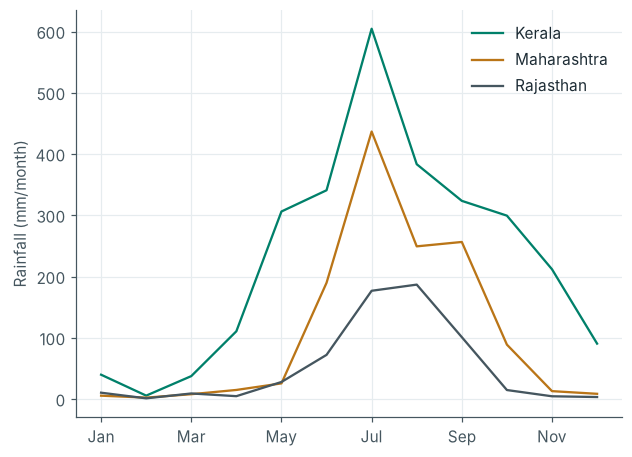

In [6]:
monthly = states.resample('MS').sum()
monthly.groupby(monthly.index.month_name().str[:3], sort=False).mean().plot(xlabel='', ylabel='Rainfall (mm/month)');

`by=` splits a region into its parts, here the districts of Maharashtra.

In [7]:
districts = data.region(state='Maharashtra', by='district')

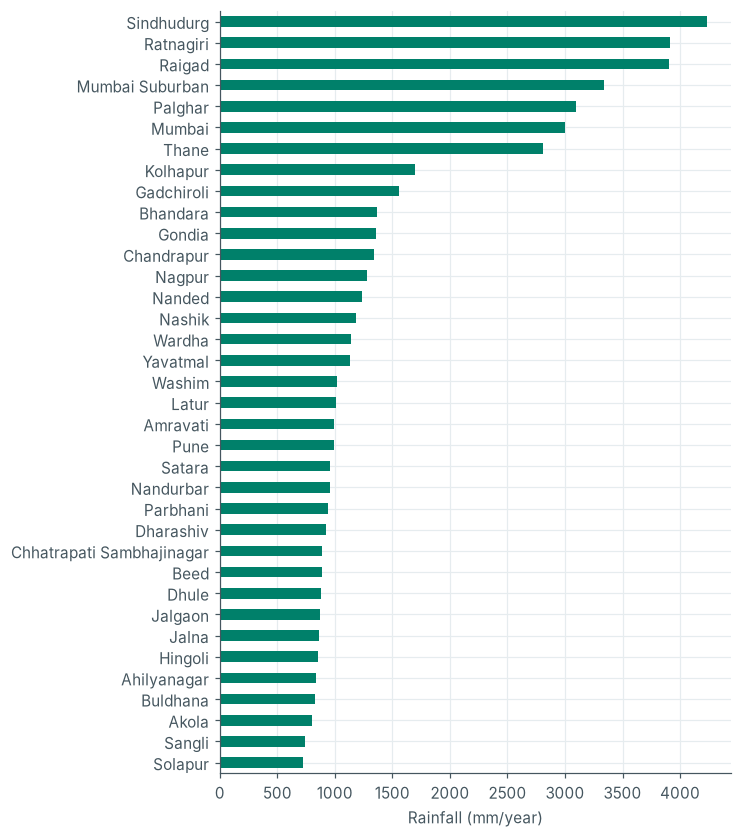

In [8]:
annual = districts.resample('YE').sum().mean().sort_values().rename(lambda n: n.split(' (')[0])
annual.plot.barh(figsize=(6, 9), xlabel='Rainfall (mm/year)');

The same works for temperature. The hottest day of April to June 2024 in two cities:

In [9]:
tmax.region(city=['Delhi', 'Chennai']).max().round(1)

Delhi (Delhi)           46.9
Chennai (Tamil Nadu)    41.4
dtype: float64

## Finding names

Names ignore case and accents, and old names work too.

In [10]:
imd.regions.search('Bombay', limit=5)

,name,type,state,district,matched_alias
0,Mumbai,district,Maharashtra,,Bombay
1,Mumbai,city,Maharashtra,Mumbai Suburban,Bombay
2,Mumbai Suburban,district,Maharashtra,,Bombay Suburban
3,Dharavi,city,Maharashtra,Mumbai,Bombay Dharavi
4,Ballard Estate,city,Maharashtra,Mumbai,Bombay Ballard Estate


In [11]:
data.region(city='Allahabad').columns     # column 'Prayagraj (Uttar Pradesh)'

Index(['Prayagraj (Uttar Pradesh)'], dtype='str')

## Clipping

`clip()` returns the grid cells of one region as a new IMD object, with NaN outside.

In [12]:
krishna_grid = data.clip(basin='Krishna')

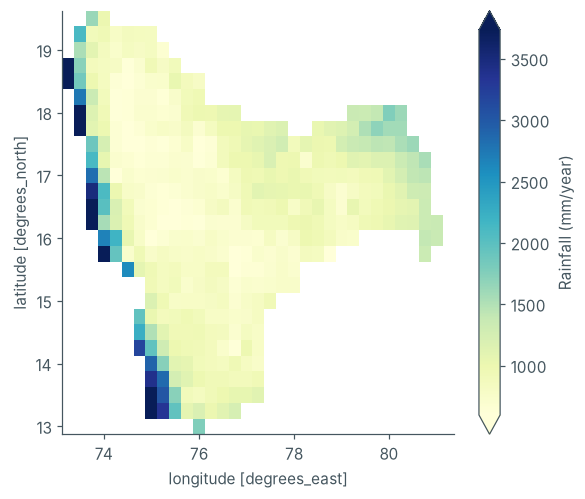

In [13]:
rain = krishna_grid.get_xarray().rain
rain.resample(time='YE').sum(min_count=1).mean('time').plot(cmap='YlGnBu', size=5, aspect=1.15, robust=True, cbar_kwargs={'label': 'Rainfall (mm/year)'});